# EDA по датасету lending_club_loan_accepting

In [47]:
import pandas as pd
import numpy as np
import sklearn
from matplotlib import pyplot as plt
from narwhals.stable.v1 import exclude

from sklearn.linear_model import SGDRegressor
from sklearn.datasets import load_diabetes
from sklearn.utils import _missing


In [48]:
import warnings
warnings.filterwarnings('ignore')

In [49]:
np.random.seed(42)

In [50]:
# Загружаем версию датасета diabetes:
# Файл нужно загрузить в Colab (панель «Файлы» слева)
# или заменить путь на ссылку на raw-файл на GitHub.
# DATA_PATH = 'https://huggingface.co/datasets/codesignal/lending-club-loan-accepted/resolve/main/accepted_2007_to_2018Q4.csv'
#создаем свою новую целевую переменную
df = pd.read_csv('accepted_2007_to_2018Q4.csv')

In [51]:
mask = df['loan_status'].isin(['Fully Paid', 'Charged Off'])

df = df.loc[mask]
d = df['loan_status']

y=df['loan_status'].map({'Fully Paid': 0, 'Charged Off': 1}) #нов целевая переменная,
                                                             # но'Current' выкинул, т.к непонятно вернет кредит или нет: ?

X = df.drop(columns = 'loan_status') # признаки

In [52]:
print(f"Размеры датасета: {X.shape[0]} строк и {X.shape[1]} столбцов")
# print(d.value_counts())


Размеры датасета: 1345310 строк и 150 столбцов


In [53]:
X.info()

<class 'pandas.DataFrame'>
Index: 1345310 entries, 0 to 2260697
Columns: 150 entries, id to settlement_term
dtypes: float64(113), object(1), str(36)
memory usage: 1.5+ GB


In [54]:
print(f"Наши признаки: {X.columns}")

Наши признаки: Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade',
       ...
       'hardship_payoff_balance_amount', 'hardship_last_payment_amount',
       'disbursement_method', 'debt_settlement_flag',
       'debt_settlement_flag_date', 'settlement_status', 'settlement_date',
       'settlement_amount', 'settlement_percentage', 'settlement_term'],
      dtype='str', length=150)


Признаки(см.discription)

In [55]:
X.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
5,68426831,NaN,11950.0,11950.0,11950.0,36 months,13.44,405.18,C,C3,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


Датасет большой, поэтому поиграемся с типами, чтобы уменьшить его вес

In [56]:
X.memory_usage(deep=True).sum() / 1024

np.float64(3555496.8837890625)

In [57]:
X.shape


(1345310, 150)

In [58]:
X.info(memory_usage='deep')

<class 'pandas.DataFrame'>
Index: 1345310 entries, 0 to 2260697
Columns: 150 entries, id to settlement_term
dtypes: float64(113), object(1), str(36)
memory usage: 3.4 GB


In [59]:
col_str = X.select_dtypes(exclude=['number','object']).columns
X[col_str] = X[col_str].astype('category')

In [60]:
fcols = X.select_dtypes('float').columns
X[fcols] = X[fcols].apply(pd.to_numeric, downcast='float')

In [61]:
X.memory_usage(deep=True).sum() / 1024

np.float64(3019474.9306640625)

In [62]:
X.describe().round(2)

,member_id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,fico_range_low,...,deferral_term,hardship_amount,hardship_length,hardship_dpd,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,settlement_amount,settlement_percentage,settlement_term
count,0.0,1345310.00,1345310.00,1345310.00,1345310.00,1345310.00,1345310.00,1344936.00,1345310.00,1345310.00,...,5754.0,5754.00,5754.0,5754.00,3759.00,5754.00,5754.00,33276.00,33276.00,33276.00
mean,NaN,14419.97,14411.56,14389.14,13.24,438.08,76247.64,18.28,0.32,696.19,...,3.0,147.43,3.0,13.95,410.70,10995.14,184.69,5029.93,47.69,13.16
std,NaN,8717.05,8713.12,8715.49,4.77,261.51,69925.10,11.16,0.88,31.85,...,0.0,128.47,0.0,9.78,357.51,7474.26,196.46,3684.83,7.31,8.24
min,NaN,500.00,500.00,0.00,5.31,4.93,0.00,-1.00,0.00,625.00,...,3.0,0.64,3.0,0.00,1.92,55.73,0.01,44.21,0.20,0.00
25%,NaN,8000.00,8000.00,7875.00,9.75,248.48,45780.00,11.79,0.00,670.00,...,3.0,53.27,3.0,5.00,147.45,5037.31,39.57,2228.62,45.00,6.00
50%,NaN,12000.00,12000.00,12000.00,12.74,375.43,65000.00,17.61,0.00,690.00,...,3.0,109.82,3.0,15.00,303.45,9305.10,120.97,4174.68,45.00,14.00
75%,NaN,20000.00,20000.00,20000.00,15.99,580.73,90000.00,24.06,0.00,710.00,...,3.0,203.35,3.0,23.00,564.82,15302.36,267.61,6884.24,50.00,18.00
max,NaN,40000.00,40000.00,40000.00,30.99,1719.83,10999200.00,999.00,39.00,845.00,...,3.0,943.94,3.0,37.00,2343.15,39542.45,1407.86,33601.00,521.35,181.00


In [63]:
X.describe(include='object')

,id,term,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,issue_d,pymnt_plan,...,hardship_status,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_loan_status,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date
count,1345310,1345310,1345310,1345310,1259525,1266799,1345310,1345310,1345310,1345310,...,5754,5754,5754,5754,5754,1345310,1345310,33276,33276,33276
unique,1345310,2,7,35,378353,11,6,3,139,1,...,2,26,25,25,5,2,2,83,3,89
top,68407277,36 months,B,C1,Teacher,10+ years,MORTGAGE,Source Verified,Mar-2016,n,...,COMPLETED,Sep-2017,Dec-2017,Oct-2017,Late (16-30 days),Cash,N,Jan-2019,COMPLETE,Jan-2019
freq,1,1020743,392741,85494,21268,442199,665579,521273,48937,1345310,...,3759,1493,1108,1065,2596,1338410,1312034,2451,14497,1635


## "Грубый" черновой вариант предварительной очистки данных

## Очистка данных

По `describe()` уже видно несколько проблем:

* в строке `count` у некоторых признаков меньше 2260701 значений — значит, есть **пропуски**;
* признаки в **разных масштабах**: `loan_amnt` меняется от 500 до 40000, а например, `hardship_dpd` — от 0.00 до 37.00.

Разберёмся с каждой проблемой по очереди.

### Шаг 1. Пропуски

Посчитаем, сколько пропусков в каждом признаке.

In [64]:
missing = X.isna().sum()

missing_df = pd.DataFrame({
    'пропусков': missing,
    'доля, %': (missing / len(X) * 100).round(3),
})[missing > 0]
print(f"Всего пропусков в: {len(missing_df)} признаках")
missing_df.sort_values(by = 'доля, %', ascending=False)

Всего пропусков в: 105 признаках


,пропусков,"доля, %"
member_id,1345310,100.000
next_pymnt_d,1345310,100.000
orig_projected_additional_accrued_interest,1341551,99.721
hardship_length,1339556,99.572
hardship_dpd,1339556,99.572
...,...,...
collections_12_mths_ex_med,56,0.004
chargeoff_within_12_mths,56,0.004
tax_liens,39,0.003
zip_code,1,0.000


In [65]:
no_missing = missing[missing==0]
print(len(no_missing))
print(no_missing.index.tolist())
more_50 = missing_df[missing_df['доля, %']>50]
print("Кол-во признаков с долей пропусков выше 50%:",len(more_50))
print(more_50.index.tolist())

45
['id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'pymnt_plan', 'url', 'purpose', 'addr_state', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'open_acc', 'pub_rec', 'revol_bal', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_amnt', 'last_fico_range_high', 'last_fico_range_low', 'policy_code', 'application_type', 'acc_now_delinq', 'delinq_amnt', 'hardship_flag', 'disbursement_method', 'debt_settlement_flag']
Кол-во признаков с долей пропусков выше 50%: 58
['member_id', 'desc', 'mths_since_last_delinq', 'mths_since_last_record', 'next_pymnt_d', 'mths_since_last_major_derog', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 'open_act_il', 'open_il

В 105 признаках есть пропуски, в 45 - нет. Выше 50 % пропусков есть в 44 признаках. В столбце member_id их 100%, около 99% в столбцах: orig_projected_additional_accrued_interest, hardship_payoff_balance_amount, hardship_last_payment_amount, payment_plan_start_date. P.S. пропусков нету только

Удалим предварительно все признаки с пропусками более 50 %: 44 шт.

In [66]:
#оставим без пропусков
X = X[no_missing.index]

In [67]:
print(f"Признаков осталось : {X.shape[1]}")

Признаков осталось : 45


Проверим формат данных и убедимся, что пропусков не осталось.

In [68]:
X.info()

<class 'pandas.DataFrame'>
Index: 1345310 entries, 0 to 2260697
Data columns (total 45 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   id                       1345310 non-null  object 
 1   loan_amnt                1345310 non-null  float32
 2   funded_amnt              1345310 non-null  float32
 3   funded_amnt_inv          1345310 non-null  float64
 4   term                     1345310 non-null  str    
 5   int_rate                 1345310 non-null  float32
 6   installment              1345310 non-null  float32
 7   grade                    1345310 non-null  str    
 8   sub_grade                1345310 non-null  str    
 9   home_ownership           1345310 non-null  str    
 10  annual_inc               1345310 non-null  float64
 11  verification_status      1345310 non-null  str    
 12  issue_d                  1345310 non-null  str    
 13  pymnt_plan               1345310 non-null  str    
 14  ur

## Целевая переменная

In [69]:
y.head()

0    0
1    0
2    0
4    0
5    0
Name: loan_status, dtype: int64

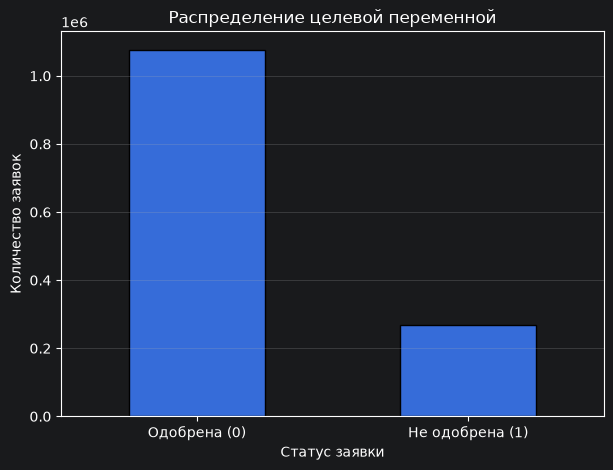

In [70]:
counts = y.value_counts().sort_index()

counts.plot(kind='bar', edgecolor='black', figsize=(7, 5))

plt.xticks([0, 1], ['Одобрена (0)', 'Не одобрена (1)'], rotation=0)
plt.xlabel('Статус заявки')
plt.ylabel('Количество заявок')
plt.title('Распределение целевой переменной')
plt.grid(axis='y', alpha=0.3)
plt.show()

Видно, что в распределение целевой переменной наблюдается дисбаланс.

In [71]:
y.head()

0    0
1    0
2    0
4    0
5    0
Name: loan_status, dtype: int64

Посмотрим на корреляции

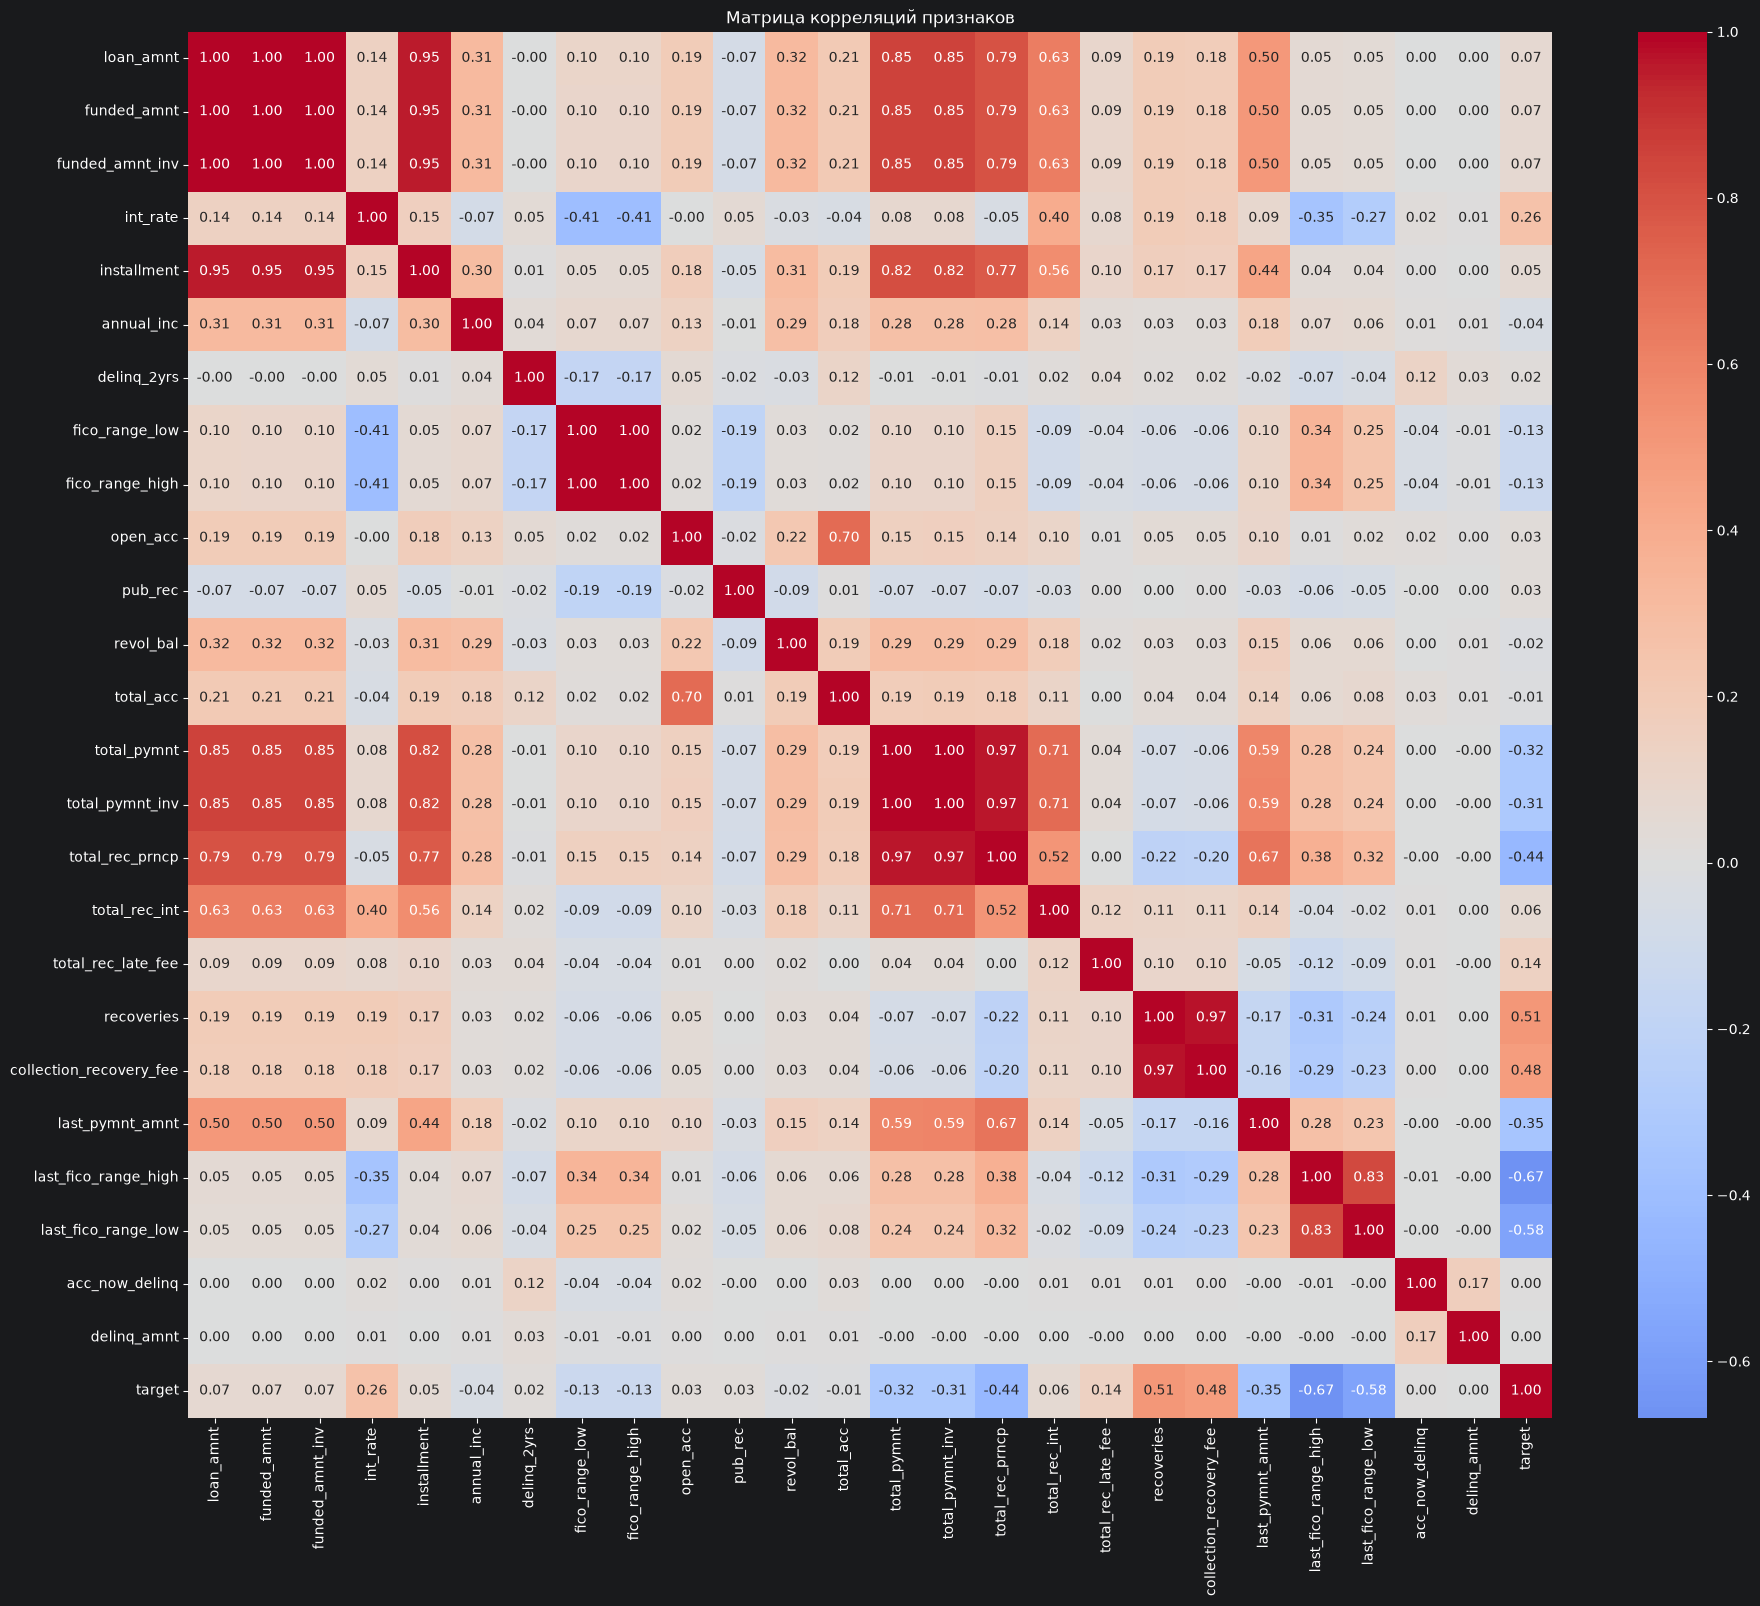

In [72]:
import seaborn as sns

X_numeric = X.select_dtypes(include='number').copy()
constant = X_numeric.columns[X_numeric.nunique()==1]
X_numeric = X_numeric.drop(columns = constant)

X_numeric['target'] = y

plt.figure(figsize=(22, 18))

sns.heatmap(
    X_numeric.corr(),
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f'
)

plt.title('Матрица корреляций признаков')
plt.show()

Среднюю по величине корреляцию с target имеют признаки: recoveries 0.51; collection_recovery_fee 0.48. Отрицацельню по величине, т.е. обратно коррелируемые величины: last_fico_range_high -0.67, last_fico_range_low -0.58, total_rec_prncp -0.44. Также сильно коррелируемыми между собой признаками являются: last_fico_range_low - last_fico_range_high (0.85); installment c loan_amnt, funded_amnt, loan_amnt. Коэффициент корреляции с каждым 0.95. А у всех трех перечисленных показатель к-та 1.

In [73]:
print(X_numeric.nunique())

loan_amnt                     1556
funded_amnt                   1556
funded_amnt_inv               9016
int_rate                       654
installment                  83307
annual_inc                   64362
delinq_2yrs                     31
fico_range_low                  40
fico_range_high                 40
open_acc                        84
pub_rec                         37
revol_bal                    83810
total_acc                      142
total_pymnt                1261726
total_pymnt_inv            1012584
total_rec_prncp             204881
total_rec_int               517185
total_rec_late_fee            9281
recoveries                  132470
collection_recovery_fee     134534
last_pymnt_amnt             693278
last_fico_range_high            72
last_fico_range_low             71
acc_now_delinq                   8
delinq_amnt                   2005
target                           2
dtype: int64


У policy_code отсутствуют уникальные значения. У него только одно значение для всех объектов. Соттветственно у него отсутствует дисперсия, поэтому и коэффициент корреляции отсутствует. По факту его тоже можно удалить.

### Шаг 2. Ошибочные значения

Ошибочные значения — это не просто «выбросы», а значения, которые **физически невозможны**. Чтобы их найти, нужны знания о предметной области.

Сначала посмотрим глазами: нарисуем boxplot для каждого признака **на отдельном графике**. На одном общем графике признаки с маленьким масштабом превратились бы в точку.

In [80]:
#список всех числовых признаков
numeric_cols = X_numeric.select_dtypes(include = 'number').columns
print("Кол-во числовых признаков:", len(numeric_cols))
# print(numeric_cols.tolist())

Кол-во числовых признаков: 26


In [82]:
#отберем те числовые признаки, у которых пропусков < 50 %
missing_percent = X_numeric.isna().mean() * 100
selected_cols = [col for col in numeric_cols]
print(len(selected_cols))

26


In [84]:
#какие типы и уникальные значения есть
for col in selected_cols:
    print(col, '-', X_numeric[col].dtype, '-',X_numeric[col].nunique() )

loan_amnt - float32 - 1556
funded_amnt - float32 - 1556
funded_amnt_inv - float64 - 9016
int_rate - float32 - 654
installment - float32 - 83307
annual_inc - float64 - 64362
delinq_2yrs - float32 - 31
fico_range_low - float32 - 40
fico_range_high - float32 - 40
open_acc - float32 - 84
pub_rec - float32 - 37
revol_bal - float32 - 83810
total_acc - float32 - 142
total_pymnt - float64 - 1261726
total_pymnt_inv - float64 - 1012584
total_rec_prncp - float64 - 204881
total_rec_int - float64 - 517185
total_rec_late_fee - float32 - 9281
recoveries - float64 - 132470
collection_recovery_fee - float32 - 134534
last_pymnt_amnt - float64 - 693278
last_fico_range_high - float32 - 72
last_fico_range_low - float32 - 71
acc_now_delinq - float32 - 8
delinq_amnt - float32 - 2005
target - int64 - 2


policy_code, deferral_term, hardship_length -только одно постоянное знач-е

#Построим ящики с усами для некоторых финансовых показателей

In [77]:
#Финансовые показатели (todo "надо исправить")
# selected_cols = [
#     'loan_amnt',
#     'installment',
#     'annual_inc',
#     'dti',
#     'revol_bal',
#     'revol_util',
#     'tot_cur_bal',
#     'avg_cur_bal',
#     'total_acc',
#     'bc_util'
# ]


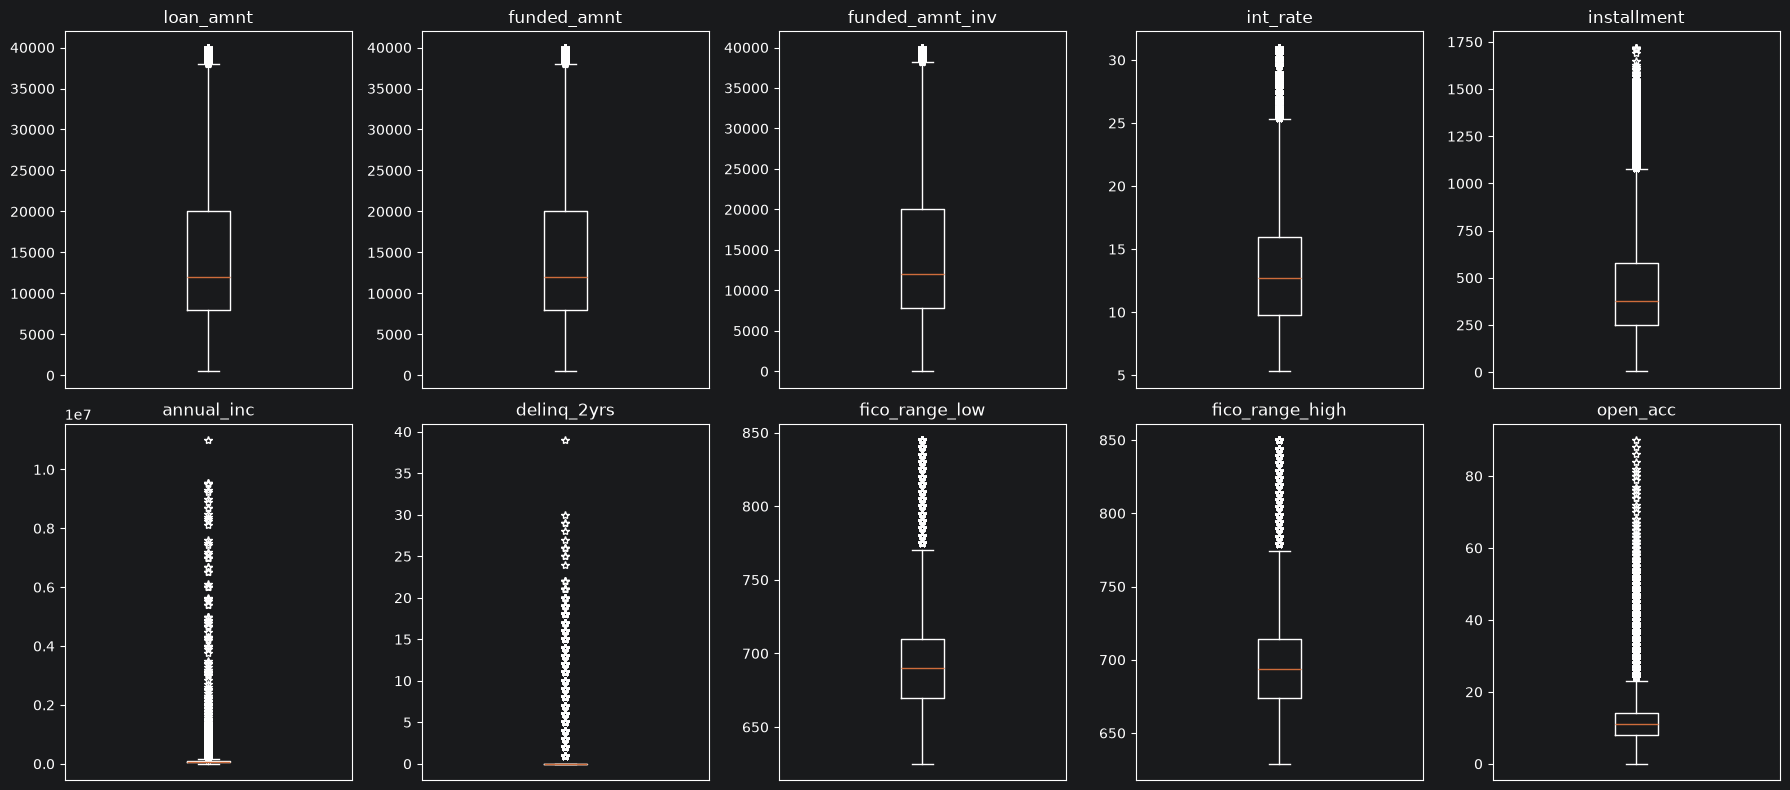

In [87]:
def boxes_with_mastashes(x,y, signs):
    fig, axes = plt.subplots(x, y, figsize=(18, 8))
    for ax, col in zip(axes.flat, signs):
        ax.boxplot(X[col].dropna(), sym='*') #sym='*' showfliers=False
        ax.set_title(col)
        ax.set_xticks([])
    plt.tight_layout()
    plt.show()

boxes_with_mastashes(2,5,selected_cols)

У половины заемщиков доход не выше

In [ ]:
#(todo "надо исправить и доделать")
check_cols = [
    'annual_inc',
    'dti',
    'revol_util',
    'revol_bal',
    'tot_cur_bal',
    'avg_cur_bal',
    'bc_util'
]

X[check_cols].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
).T